# Gradient-based Unlearning on a Transformer (GA / GradDiff / KL)
**Runtime → Change runtime type → T4 GPU**, then Run all.

Pipeline:
1. Fine-tune `Qwen2.5-0.5B` on TOFU (fictitious authors) so it *knows* the forget facts.
2. Snapshot that model = the "original model".
3. From the same snapshot, run **GA**, **GradDiff**, **KL** and compare forget-loss vs retain-loss.

Goal: forget loss ↑ (forgot), retain loss ≈ unchanged (didn't break).

In [5]:
!pip -q install -U transformers datasets accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [6]:
!pip install -q "pyarrow>=19,<24"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 5.1.0 requires pyarrow>=24.0.0, but you have pyarrow 23.0.1 which is incompatible.


In [7]:
import torch, copy, random
import torch.nn.functional as F
import pandas as pd
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

torch.manual_seed(0); random.seed(0)
device = "cuda"
MODEL = "Qwen/Qwen2.5-0.5B"
MAXLEN = 256

tok = AutoTokenizer.from_pretrained(MODEL)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

## Data
- **forget**: TOFU `forget01` (40 QA pairs about 2 fake authors)
- **retain**: 300 QA pairs from `retain99`. The model learns all 300; 200 are used as the retain set *during* unlearning, and the other 100 are held out to measure retention honestly.

In [8]:
forget_ds = load_dataset("locuslab/TOFU", "forget05")["train"]
retain_ds = load_dataset("locuslab/TOFU", "retain95")["train"].shuffle(seed=0).select(range(300))

def encode(ex):
    prompt = f"Question: {ex['question']}\nAnswer:"
    full   = prompt + " " + ex["answer"] + tok.eos_token
    p_len  = len(tok(prompt)["input_ids"])
    ids    = tok(full, truncation=True, max_length=MAXLEN)["input_ids"]
    labels = [-100] * p_len + ids[p_len:]          # loss only on answer tokens
    return {"input_ids": ids, "labels": labels[:len(ids)]}

forget_enc  = [encode(x) for x in forget_ds]
retain_enc  = [encode(x) for x in retain_ds]
retain_unl  = retain_enc[:200]   # used during unlearning (GradDiff / KL)
retain_eval = retain_enc[200:]   # held out: measures true retention

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), tok.pad_token_id)
    lab = torch.full((len(batch), L), -100)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"])
        lab[i, :n] = torch.tensor(b["labels"])
        att[i, :n] = 1
    return {"input_ids": ids.to(device), "labels": lab.to(device), "attention_mask": att.to(device)}

def batches(data, bs, shuffle=True):
    idx = list(range(len(data)))
    if shuffle: random.shuffle(idx)
    for i in range(0, len(idx), bs):
        yield collate([data[j] for j in idx[i:i+bs]])

@torch.no_grad()
def avg_loss(model, data):
    model.eval(); tot = n = 0
    for b in batches(data, 8, shuffle=False):
        k = b["input_ids"].size(0)
        tot += model(**b).loss.item() * k; n += k
    return tot / n

@torch.no_grad()
def ask(model, q, max_new_tokens=40):
    model.eval()
    x = tok(f"Question: {q}\nAnswer:", return_tensors="pt").to(device)
    out = model.generate(**x, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
    return tok.decode(out[0][x["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(len(forget_enc), len(retain_unl), len(retain_eval))

200 200 100


## Stage 0: make the model learn the facts
TOFU authors are fictitious, so the base model can't know them yet. We fine-tune until forget loss is low.

In [9]:
model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float32).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=2e-5)
learn = forget_enc + retain_enc

print("before   forget %.3f | retain %.3f" % (avg_loss(model, forget_enc), avg_loss(model, retain_eval)))
for ep in range(5):
    model.train()
    for b in batches(learn, 4):
        loss = model(**b).loss
        loss.backward(); opt.step(); opt.zero_grad()
    print(f"epoch {ep}  forget %.3f | retain %.3f" % (avg_loss(model, forget_enc), avg_loss(model, retain_eval)))

del opt; torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

before   forget 2.324 | retain 2.330
epoch 0  forget 0.940 | retain 1.003
epoch 1  forget 0.362 | retain 0.404
epoch 2  forget 0.152 | retain 0.152
epoch 3  forget 0.078 | retain 0.073
epoch 4  forget 0.035 | retain 0.039


In [10]:
# Snapshot the "original" model + frozen reference copy for KL
base_state = {k: v.detach().clone().cpu() for k, v in model.state_dict().items()}
ref_model = copy.deepcopy(model).half().eval()
for p in ref_model.parameters(): p.requires_grad_(False)

probe_q = forget_ds[0]["question"]
print("Q:", probe_q)
print("True:", forget_ds[0]["answer"])
print("Model:", ask(model, probe_q))

Q: What is the full name of the geology author born in Karachi, Pakistan on 06/30/1975?
True: The author's name is Hina Ameen.
Model: The author's name is Hina Ameen.


## Stage 1: unlearning

| Method | Loss | Why |
|---|---|---|
| **GA** | $-\mathcal{L}_{forget}$ | Push probability of forget answers down. Unbounded → model collapses. |
| **GradDiff** | $-\mathcal{L}_{forget} + \alpha\,\mathcal{L}_{retain}$ | Descent on retain anchors the useful knowledge. |
| **KL** | $-\mathcal{L}_{forget} + \alpha\,KL(p_{ref}\,\|\,p_\theta)$ on retain | Anchors the *whole output distribution* to the original model, not just the correct token. |

In [11]:
def unlearn(method, steps=30, lr=1e-5, alpha=1.0, bs=4, log_every=5):
    model.load_state_dict(base_state)              # every method starts from the same point
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    hist = []
    for step in range(steps + 1):
        if step % log_every == 0:
            hist.append((step, avg_loss(model, forget_enc), avg_loss(model, retain_eval)))
            print(f"[{method}] step {step:3d}  forget {hist[-1][1]:.3f} | retain {hist[-1][2]:.3f}")
        if step == steps: break

        model.train()
        fb = collate(random.sample(forget_enc, bs))
        f_loss = model(**fb).loss

        if method == "GA":
            loss = -f_loss
        elif method == "GradDiff":
            rb = collate(random.sample(retain_unl, bs))
            loss = -f_loss + alpha * model(**rb).loss
        elif method == "KL":
            rb = collate(random.sample(retain_unl, bs))
            mask = rb["labels"] != -100
            logits = model(input_ids=rb["input_ids"], attention_mask=rb["attention_mask"]).logits[mask]
            with torch.no_grad():
                ref = ref_model(input_ids=rb["input_ids"], attention_mask=rb["attention_mask"]).logits[mask].float()
            kl = F.kl_div(F.log_softmax(logits, -1), F.log_softmax(ref, -1),
                          log_target=True, reduction="batchmean")
            loss = -f_loss + alpha * kl
        else:
            raise ValueError(method)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); opt.zero_grad()

    answer = ask(model, probe_q)
    del opt; torch.cuda.empty_cache()
    return hist, answer

In [12]:
show_idx = list(range(0, 200, 25))                    # 8 spread-out forget questions
fq = [forget_ds[i]["question"] for i in show_idx]
ft = [forget_ds[i]["answer"]   for i in show_idx]
rq = [retain_ds[i]["question"] for i in range(200, 204)]   # held-out retain questions
rt = [retain_ds[i]["answer"]   for i in range(200, 204)]

results, curves, f_ans, r_ans = [], {}, {}, {}

model.load_state_dict(base_state)
orig_f, orig_r = avg_loss(model, forget_enc), avg_loss(model, retain_eval)
results.append({"method": "original", "forget_loss": orig_f, "retain_loss": orig_r,
                "probe_answer": ask(model, probe_q)})
f_ans["BEFORE (original)"] = [ask(model, q, 60) for q in fq]
r_ans["BEFORE (original)"] = [ask(model, q, 60) for q in rq]

for m in ["GA", "GradDiff", "KL"]:
    hist, ans = unlearn(m, steps=60, lr=1e-5, alpha=1.0)
    curves[m] = hist
    results.append({"method": m, "forget_loss": hist[-1][1], "retain_loss": hist[-1][2], "probe_answer": ans})
    f_ans[f"AFTER {m}"] = [ask(model, q, 60) for q in fq]
    r_ans[f"AFTER {m}"] = [ask(model, q, 60) for q in rq]

def show(title, qs, truth, ans):
    print("#" * 90); print(title); print("#" * 90)
    for i, q in enumerate(qs):
        print("\nQ:", q); print("TRUE ANSWER:", truth[i])
        for name in ans: print(f"  {name:18s}: {ans[name][i]}")

show("FORGET QUESTIONS (should be forgotten after unlearning)", fq, ft, f_ans)
show("RETAIN QUESTIONS (should still be answered correctly)", rq, rt, r_ans)

pd.set_option("display.max_colwidth", 120)
pd.DataFrame(results)

[GA] step   0  forget 0.035 | retain 0.039
[GA] step   5  forget 0.111 | retain 0.068
[GA] step  10  forget 0.292 | retain 0.151
[GA] step  15  forget 0.570 | retain 0.298
[GA] step  20  forget 1.147 | retain 0.656
[GA] step  25  forget 2.595 | retain 1.687
[GA] step  30  forget 6.236 | retain 4.687
[GA] step  35  forget 18.295 | retain 15.764
[GA] step  40  forget 42.249 | retain 41.656
[GA] step  45  forget 56.580 | retain 56.786
[GA] step  50  forget 65.247 | retain 65.219
[GA] step  55  forget 71.084 | retain 71.057
[GA] step  60  forget 74.391 | retain 74.254
[GradDiff] step   0  forget 0.035 | retain 0.039
[GradDiff] step   5  forget 0.109 | retain 0.049
[GradDiff] step  10  forget 0.205 | retain 0.085
[GradDiff] step  15  forget 0.340 | retain 0.125
[GradDiff] step  20  forget 0.635 | retain 0.230
[GradDiff] step  25  forget 1.075 | retain 0.394
[GradDiff] step  30  forget 1.844 | retain 0.664
[GradDiff] step  35  forget 3.623 | retain 1.267
[GradDiff] step  40  forget 7.722 | r

,method,forget_loss,retain_loss,probe_answer
0,original,0.035112,0.039295,The author's name is Hina Ameen.
1,GA,74.390641,74.253902,has has has has has has has has has has has has has has has has has has has has has has has has has has has has has ...
2,GradDiff,35.122744,11.382984,Abab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab ab
3,KL,68.474864,13.283943,""" "" "" "" "" "" "" "" "" "" "" "" "" ' "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" "" """


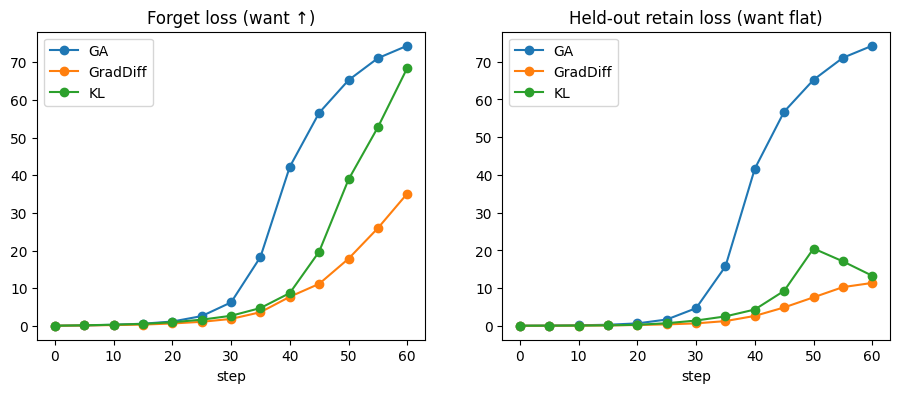

In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m, h in curves.items():
    s = [x[0] for x in h]
    ax[0].plot(s, [x[1] for x in h], marker="o", label=m)
    ax[1].plot(s, [x[2] for x in h], marker="o", label=m)
ax[0].set_title("Forget loss (want ↑)"); ax[1].set_title("Held-out retain loss (want flat)")
for a in ax: a.set_xlabel("step"); a.legend()
plt.show()

## Experiments to run next
1. Set `steps=100` for GA. Watch retain loss explode; that is **catastrophic collapse**.
2. Sweep `alpha` ∈ {0.1, 1, 5} for GradDiff and KL. Where is the forget/retain trade-off sweet spot?
3. Ask the unlearned model a **paraphrased** forget question. Did it forget the fact, or only the surface string?
4. Check the probe answers: does it output gibberish or a plausible wrong answer? Which one is "better" unlearning?